<a href="https://colab.research.google.com/github/wadeea23/Facial-Emotion-Recognition.lab/blob/main/wadeea_lab_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report ,recall_score


**part 1**

In [2]:
zip_path = "/content/drive/MyDrive/GA/labNN.zip"
extract_path = "/content/labNN"

In [3]:
test_path = os.path.join(extract_path, "test")
train_path = os.path.join(extract_path, "train")
emotions = os.listdir(train_path) ## to known every feeling how many pic in thair
for i in emotions:
    print(i, len(os.listdir(os.path.join(train_path, i))))

happy 7215
sad 4830
neutral 4965
disgust 436
angry 3995
surprise 3171
fear 4097


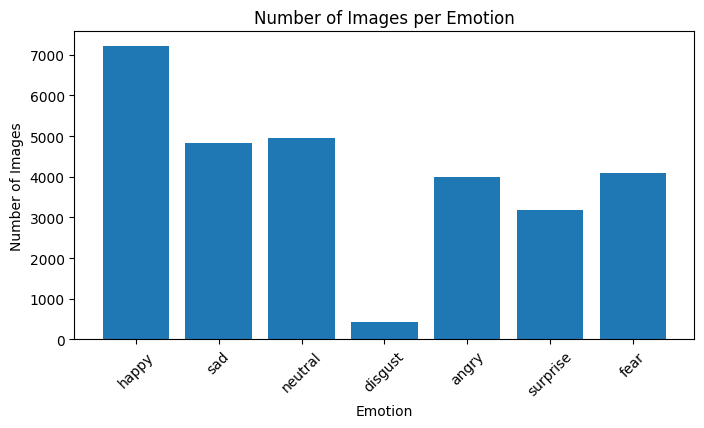

In [4]:
plt.figure(figsize=(8, 4))
plt.bar(emotions, [
    len(os.listdir(os.path.join(train_path, i)))
    for i in emotions])

plt.title("Number of Images per Emotion")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

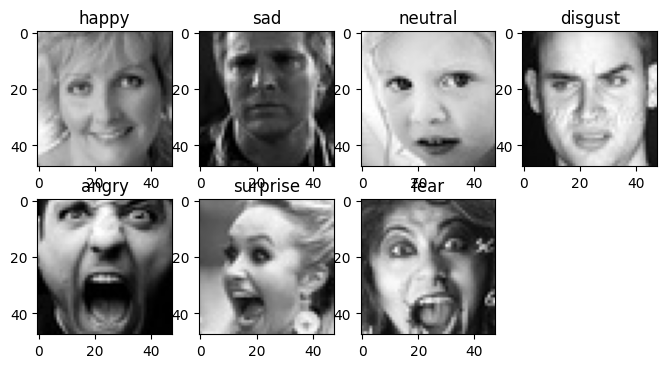

In [5]:
plt.figure(figsize=(8, 4))
for i in range(len(emotions)):
    plt.subplot(2, 4, i + 1)
    img = Image.open(os.path.join(train_path, emotions[i], os.listdir(os.path.join(train_path, emotions[i]))[0]))
    plt.imshow(img,cmap="gray")
    plt.title(emotions[i])

the data is imbalanced has far fewer images than the other,
the image are 48x48 ,samplesare mostly clear



In [6]:
X_train = []
y_train = []
for label,i in enumerate(emotions):
    for j in os.listdir(os.path.join(train_path, i)):
        img = Image.open(os.path.join(train_path, i, j))
        img = img.resize((48, 48))
        img = np.array(img)
        X_train.append(img)
        y_train.append(label)
X_train=np.array(X_train)
y_train=np.array(y_train)
print(X_train.shape,y_train.shape)

(28709, 48, 48) (28709,)


In [7]:
X_test = []
y_test = []
for label,i in enumerate(emotions):
    for j in os.listdir(os.path.join(test_path, i)):
        img = Image.open(os.path.join(test_path, i, j))
        img = img.resize((48, 48))
        img = np.array(img)
        X_test.append(img)
        y_test.append(label)
X_test=np.array(X_test)
y_test=np.array(y_test)
print(X_test.shape,y_test.shape)


(7178, 48, 48) (7178,)


In [8]:
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

In [9]:
#normalized to 0,1
X_train=X_train/255
X_val=X_val/255
X_test=X_test/255
print(X_train.min(), X_train.max())

0.0 1.0


**PART 2**
Neural Network

In [10]:
model = Sequential()
model.add(Input(shape=(48, 48)))
model.add(Flatten())
model.add(Dense(128))
model.add(Activation('relu'))
model.add(Dense(7))
model.add(Activation('softmax'))


In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 7)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 295,943 (1.13 MB)

 Trainable params: 295,943 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['acc'])

In [13]:
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_val, y_val))

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - acc: 0.2722 - loss: 1.7903 - val_acc: 0.3328 - val_loss: 1.7138
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - acc: 0.3144 - loss: 1.7205 - val_acc: 0.3199 - val_loss: 1.7071
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - acc: 0.3329 - loss: 1.6920 - val_acc: 0.3579 - val_loss: 1.6713
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3402 - loss: 1.6805 - val_acc: 0.3281 - val_loss: 1.6816
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - acc: 0.3492 - loss: 1.6625 - val_acc: 0.3603 - val_loss: 1.6661
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - acc: 0.3524 - loss: 1.6549 - val_acc: 0.3220 - val_loss: 1.7086
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - acc: 0.3511 - loss: 1.6468 - val_acc: 0.3257 - val_loss: 1.7014
Epoch 8/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3528 - loss: 1.6434 - val_acc: 0.3696 - val_loss: 1.6290
Epoch 9/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step -

<Axes: >

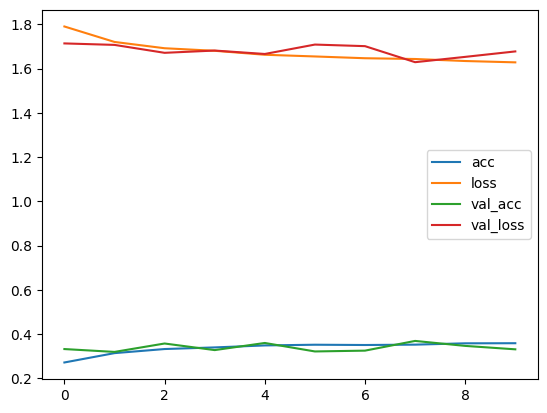

In [14]:
pd.DataFrame(history.history).plot()

In [15]:
teat_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", teat_loss)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.3420 - loss: 1.6730
Test Accuracy: 0.342017263174057
Test Loss: 1.6730315685272217


In [16]:
confusion_matrix(y_test, np.argmax(model.predict(X_test), axis=1))

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([[915, 146, 180,   0,  26, 176, 331],
       [187, 299, 177,   0,  35, 213, 336],
       [195, 169, 341,   0,  13, 236, 279],
       [ 25,  14,  14,   0,   6,  18,  34],
       [204, 148, 118,   0,  47, 171, 270],
       [ 65,  34,  53,   0,   6, 536, 137],
       [148, 130, 123,   0,  14, 292, 317]])

In [17]:
classification_report(y_test, np.argmax(model.predict(X_test), axis=1))

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


'              precision    recall  f1-score   support\n\n           0       0.53      0.52      0.52      1774\n           1       0.32      0.24      0.27      1247\n           2       0.34      0.28      0.30      1233\n           3       0.00      0.00      0.00       111\n           4       0.32      0.05      0.09       958\n           5       0.33      0.65      0.43       831\n           6       0.19      0.31      0.23      1024\n\n    accuracy                           0.34      7178\n   macro avg       0.29      0.29      0.26      7178\nweighted avg       0.35      0.34      0.32      7178\n'

In [18]:
recall_score(y_test, np.argmax(model.predict(X_test), axis=1), average=None)

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([0.51578354, 0.23977546, 0.27656123, 0.        , 0.04906054,
       0.64500602, 0.30957031])

**part 3 **

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
[   2    7    8 ... 7175 7176 7177]


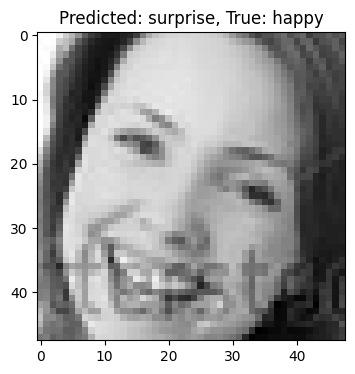

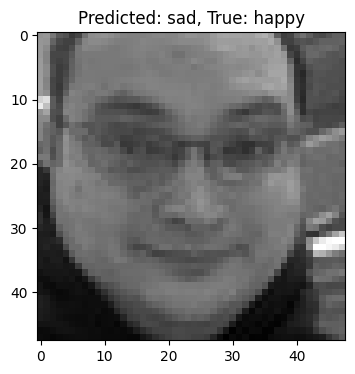

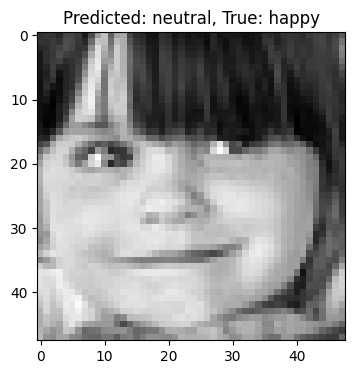

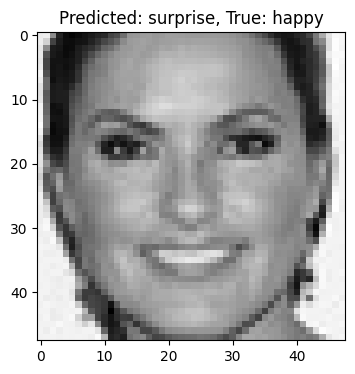

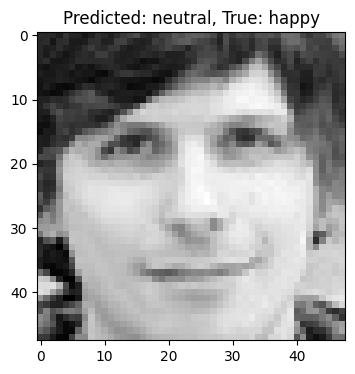

In [19]:
y_pred = model.predict(X_test)

y_pred = np.argmax(y_pred, axis=1)
y_true =np.array(y_test)

error = np.where(y_pred != y_true)[0]
print(error)

for i in error[:5]:
    plt.figure(figsize=(4, 4))
    plt.imshow(X_test[i], cmap='gray')
    plt.title(f"Predicted: {emotions[y_pred[i]]}, True: {emotions[y_true[i]]}")
    plt.show()

The model made mistakes because some emotions look similar. Some images may also be unclear or have different lighting.

In [20]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [21]:
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_val, y_val), callbacks=[early_stopping])

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - acc: 0.3678 - loss: 1.6186 - val_acc: 0.3596 - val_loss: 1.6345
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3680 - loss: 1.6145 - val_acc: 0.3701 - val_loss: 1.6158
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3723 - loss: 1.6067 - val_acc: 0.3718 - val_loss: 1.6094
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - acc: 0.3746 - loss: 1.6004 - val_acc: 0.3689 - val_loss: 1.6209
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - acc: 0.3749 - loss: 1.5990 - val_acc: 0.3628 - val_loss: 1.6296
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3764 - loss: 1.5951 - val_acc: 0.3469 - val_loss: 1.6426
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3770 - loss: 1.5921 - val_acc: 0.3666 - val_loss: 1.6155
Epoch 8/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - acc: 0.3788 - loss: 1.5851 - val_acc: 0.3675 - val_loss: 1.6134


In [22]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.3785 - loss: 1.6129
Test Accuracy: 0.37851768732070923
Test Loss: 1.612903356552124


**part 4**

In [23]:
!pip install streamlit pyngrok

In [24]:

%%writefile /content/app.py

import streamlit as st
import numpy as np
import json
from PIL import Image
from tensorflow.keras.models import load_model

# Load model and emotion names
model = load_model("/content/emotion_model.keras")

with open("/content/emotion_classes.json", "r") as f:
    classes = json.load(f)

# App title
st.title("Facial Emotion Detector")
st.write("Upload an image or open the camera.")

# Upload image
uploaded_image = st.file_uploader(
    "Upload Image",
    type=["jpg", "jpeg", "png"]
)

# Camera button
open_camera = st.checkbox("Open Camera")

camera_image = None

if open_camera:
    camera_image = st.camera_input("Take a Photo")

# Select image
if uploaded_image is not None:
    image_file = uploaded_image
elif camera_image is not None:
    image_file = camera_image
else:
    image_file = None

# Display and predict
if image_file is not None:

    image = Image.open(image_file)
    st.image(image, caption="Your Image", width=300)

    if st.button("Predict Emotion"):

        # Prepare image
        image = image.convert("L")
        image = image.resize((48, 48))
        image = np.array(image) / 255.0
        image = np.expand_dims(image, axis=0)
        image = np.expand_dims(image, axis=-1)

        # Predict emotion
        prediction = model.predict(image, verbose=0)[0]
        best_index = np.argmax(prediction)

        # Show result
        st.subheader("Predicted Emotion")
        st.success(classes[best_index].capitalize())

        # Show probabilities
        st.subheader("Emotion Probabilities")

        for i in range(len(classes)):
            st.write(classes[i].capitalize())
            st.progress(float(prediction[i]))
            st.write(f"{prediction[i] * 100:.2f}%")


Overwriting /content/app.py


In [ ]:
!streamlit run /content/app.py --server.port 8501 &>/content/logs.txt &
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼your url is: https://curvy-nights-live.loca.lt
